# Final Research Results and Dashboard

**Project:** Associations Between Cattle Growth, Supplement-Feeder Behaviour, and Environmental Conditions

This notebook consolidates the findings from the preceding data-audit and analysis notebooks. It presents the final results, research figures, and conclusions concerning cattle growth, supplement-feeder behaviour, and environmental conditions.

The analysis uses the prepared Nelore cattle dataset containing 26 animals observed across 15 periods, representing 390 animal-period records. Environmental associations are based on 15 period-level observations.

All findings will be reported transparently, distinguishing statistical associations from causal conclusions. No new research questions will be introduced.

In [2]:
# Description: Load the prepared cattle dataset for final reporting.

import pandas as pd
from pathlib import Path

file_path = Path("nelore_cattle_prepared.csv")

if not file_path.exists():
    from google.colab import files
    uploaded = files.upload()

    if "nelore_cattle_prepared.csv" not in uploaded:
        raise FileNotFoundError(
            "Please upload nelore_cattle_prepared.csv."
        )

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("Unique animals:", df["ANIMAL"].nunique())
print("Observation periods:", df["PERIOD"].nunique())
print("Required ADG column available:", "ADG_recorded" in df.columns)

Dataset shape: (390, 76)
Unique animals: 26
Observation periods: 15
Required ADG column available: True


### Final Results Summary

This section consolidates the established findings for the three research questions: cattle growth across observation periods, associations between feeder behaviour and growth, and associations between environmental conditions and growth. Reported statistical results are carried forward from Notebook 2.

In [3]:
# Description: Compile the established findings into final reporting tables.

growth_summary = pd.DataFrame({
    "Measure": [
        "Animals",
        "Observation periods",
        "Animal-period records",
        "Mean recorded ADG (kg/day)",
        "Highest period mean ADG (kg/day)",
        "Lowest period mean ADG (kg/day)"
    ],
    "Result": [
        df["ANIMAL"].nunique(),
        df["PERIOD"].nunique(),
        len(df),
        round(df["ADG_recorded"].mean(), 3),
        1.20,
        -0.13
    ]
})

feeder_results = pd.DataFrame({
    "Feeder measure": [
        "Total time at feeder",
        "Feeder attendance",
        "Days of feeder use"
    ],
    "Coefficient": [-0.00001, 0.00035, -0.00193],
    "P_value": [0.48596, 0.73773, 0.76031],
    "Significant_at_5_percent": [False, False, False]
})

environment_results = pd.DataFrame({
    "Environmental variable": [
        "Relative humidity",
        "Rainfall",
        "NDWI"
    ],
    "Initial_correlation": [0.7779, 0.5985, 0.5658],
    "Initial_p_value": [0.0006, 0.0184, 0.0279],
    "Time_adjusted_correlation": [0.6138, 0.3103, 0.1640],
    "Time_adjusted_p_value": [0.0149, 0.2604, 0.5592],
    "Time_adjusted_significant_at_5_percent": [True, False, False]
})

print("TABLE 1 — STUDY AND GROWTH SUMMARY")
display(growth_summary)

print("TABLE 2 — FEEDER-BEHAVIOUR MODELS")
display(feeder_results)

print("TABLE 3 — ENVIRONMENTAL ASSOCIATIONS")
display(environment_results)

TABLE 1 — STUDY AND GROWTH SUMMARY


,Measure,Result
0,Animals,26.000
1,Observation periods,15.000
2,Animal-period records,390.000
3,Mean recorded ADG (kg/day),0.592
4,Highest period mean ADG (kg/day),1.200
5,Lowest period mean ADG (kg/day),-0.130


TABLE 2 — FEEDER-BEHAVIOUR MODELS


,Feeder measure,Coefficient,P_value,Significant_at_5_percent
0,Total time at feeder,-0.00001,0.48596,False
1,Feeder attendance,0.00035,0.73773,False
2,Days of feeder use,-0.00193,0.76031,False


TABLE 3 — ENVIRONMENTAL ASSOCIATIONS


,Environmental variable,Initial_correlation,Initial_p_value,Time_adjusted_correlation,Time_adjusted_p_value,Time_adjusted_significant_at_5_percent
0,Relative humidity,0.7779,0.0006,0.6138,0.0149,True
1,Rainfall,0.5985,0.0184,0.3103,0.2604,False
2,NDWI,0.5658,0.0279,0.1640,0.5592,False


### Exporting Final Research Results

The consolidated tables summarize study characteristics and cattle growth, feeder-behaviour model results, and environmental associations before and after accounting for linear time trends. These tables will be exported for reproducible reporting and presentation.

In [4]:
# Description: Save the three final research tables as CSV files.

growth_summary.to_csv("final_growth_summary.csv", index=False)
feeder_results.to_csv("final_feeder_results.csv", index=False)
environment_results.to_csv("final_environment_results.csv", index=False)

print("Final results tables saved:")
print("- final_growth_summary.csv")
print("- final_feeder_results.csv")
print("- final_environment_results.csv")

Final results tables saved:
- final_growth_summary.csv
- final_feeder_results.csv
- final_environment_results.csv


### Final Research Figures

This section generates three figures covering cattle growth across observation periods, supplement-feeder behaviour in relation to growth, and environmental conditions in relation to growth. The figures use the prepared dataset and period-level data from the completed analyses.

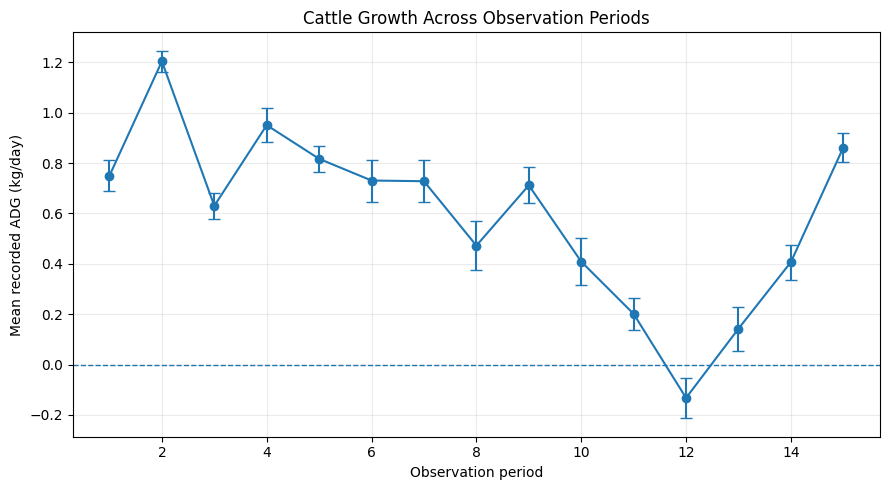

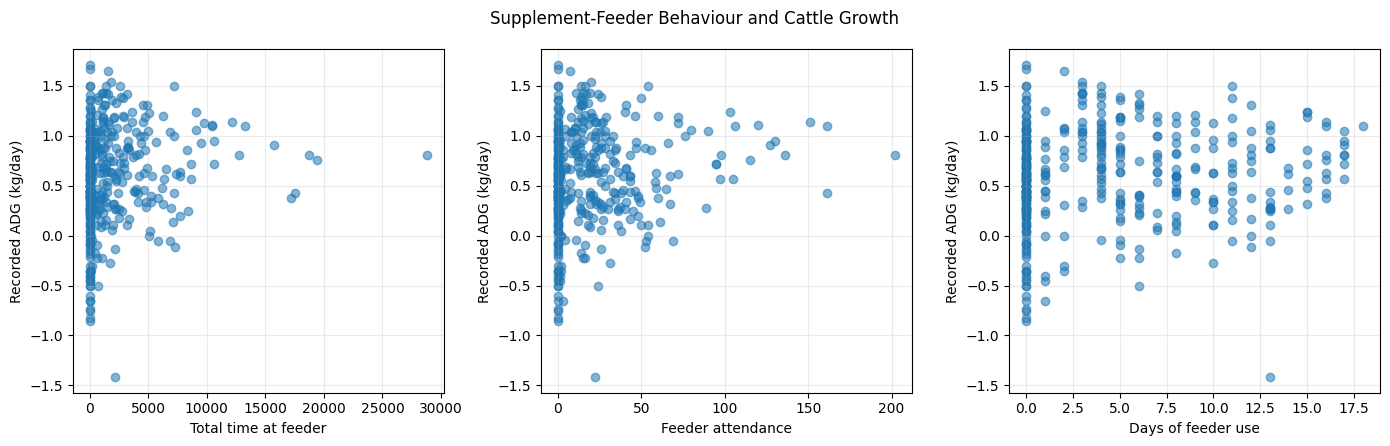

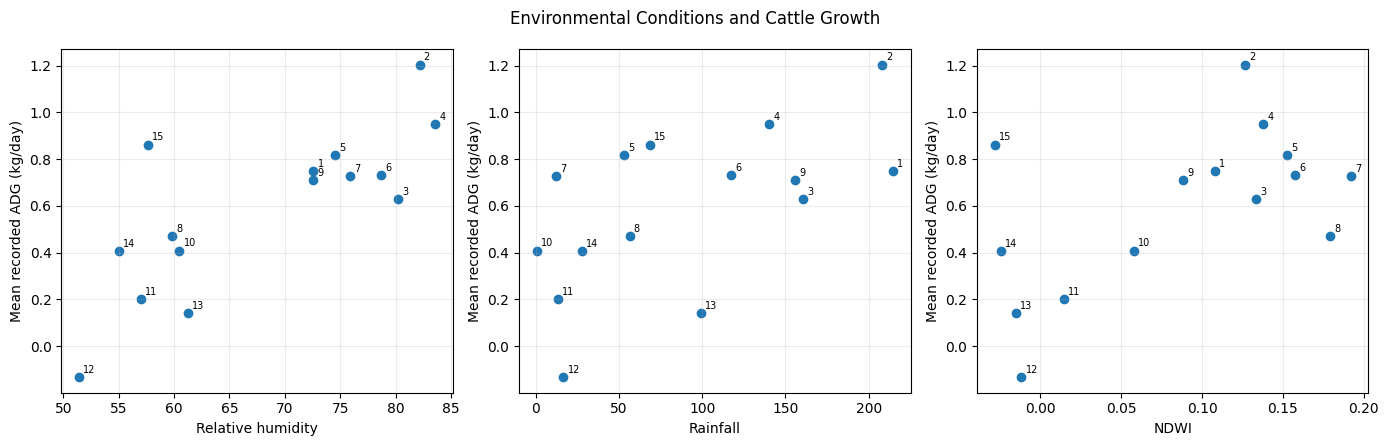

All three figures saved successfully.


In [6]:
# Description: Recreate period-level data and save all three research figures.

import matplotlib.pyplot as plt

# Recreate environmental data: one row per observation period.
environmental_variables = [
    "HUM_REL_AVG", "RAIN_SUM", "NDWI_INDEX"
]

period_data = (
    df.groupby("PERIOD")
      .agg(
          Mean_ADG=("ADG_recorded", "mean"),
          HUM_REL_AVG=("HUM_REL_AVG", "first"),
          RAIN_SUM=("RAIN_SUM", "first"),
          NDWI_INDEX=("NDWI_INDEX", "first")
      )
      .reset_index()
)

# Figure 1: Cattle growth across periods.
growth_by_period = (
    df.groupby("PERIOD")["ADG_recorded"]
      .agg(["mean", "std", "count"])
      .reset_index()
)
growth_by_period["SE"] = (
    growth_by_period["std"] / growth_by_period["count"]**0.5
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(
    growth_by_period["PERIOD"], growth_by_period["mean"],
    yerr=growth_by_period["SE"], marker="o", capsize=4
)
ax.axhline(0, linestyle="--", linewidth=1)
ax.set(xlabel="Observation period",
       ylabel="Mean recorded ADG (kg/day)",
       title="Cattle Growth Across Observation Periods")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("figure1_cattle_growth.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Figure 2: Feeder behaviour and growth.
feeder_variables = [
    ("TOTAL_TIME", "Total time at feeder"),
    ("TOTAL_ATTENDANCE", "Feeder attendance"),
    ("TOTAL_DAYS", "Days of feeder use")
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (variable, label) in zip(axes, feeder_variables):
    ax.scatter(df[variable], df["ADG_recorded"], alpha=0.55)
    ax.set_xlabel(label)
    ax.set_ylabel("Recorded ADG (kg/day)")
    ax.grid(alpha=0.25)

fig.suptitle("Supplement-Feeder Behaviour and Cattle Growth")
fig.tight_layout()
fig.savefig("figure2_feeder_behaviour.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Figure 3: Environmental conditions and growth.
environmental_variables = [
    ("HUM_REL_AVG", "Relative humidity"),
    ("RAIN_SUM", "Rainfall"),
    ("NDWI_INDEX", "NDWI")
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (variable, label) in zip(axes, environmental_variables):
    ax.scatter(period_data[variable], period_data["Mean_ADG"])

    for _, row in period_data.iterrows():
        ax.annotate(
            str(int(row["PERIOD"])),
            (row[variable], row["Mean_ADG"]),
            fontsize=7, xytext=(3, 3), textcoords="offset points"
        )

    ax.set_xlabel(label)
    ax.set_ylabel("Mean recorded ADG (kg/day)")
    ax.grid(alpha=0.25)

fig.suptitle("Environmental Conditions and Cattle Growth")
fig.tight_layout()
fig.savefig(
    "figure3_environmental_associations.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("All three figures saved successfully.")

In [7]:
# Description: Verify that all three research figures were saved.

from pathlib import Path

figure_files = [
    "figure1_cattle_growth.png",
    "figure2_feeder_behaviour.png",
    "figure3_environmental_associations.png"
]

for filename in figure_files:
    path = Path(filename)
    print(f"{filename}: {'Saved' if path.exists() else 'MISSING'}")

figure1_cattle_growth.png: Saved
figure2_feeder_behaviour.png: Saved
figure3_environmental_associations.png: Saved


In [8]:
# Description: Organize final figures and results tables for the GitHub README.

from pathlib import Path
import shutil

assets_dir = Path("github_readme_assets")
assets_dir.mkdir(exist_ok=True)

files_to_copy = [
    "figure1_cattle_growth.png",
    "figure2_feeder_behaviour.png",
    "figure3_environmental_associations.png",
    "final_growth_summary.csv",
    "final_feeder_results.csv",
    "final_environment_results.csv"
]

for filename in files_to_copy:
    source = Path(filename)

    if source.exists():
        shutil.copy2(source, assets_dir / filename)
        print(f"Copied: {filename}")
    else:
        print(f"MISSING: {filename}")

print("\nAssets folder:", assets_dir.resolve())
print("Files organized:", len(list(assets_dir.iterdir())))

Copied: figure1_cattle_growth.png
Copied: figure2_feeder_behaviour.png
Copied: figure3_environmental_associations.png
Copied: final_growth_summary.csv
Copied: final_feeder_results.csv
Copied: final_environment_results.csv

Assets folder: /content/github_readme_assets
Files organized: 6
